ABTest

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
a = np.array([23 , 21, 19, 24, 35, 17, 18, 24, 33, 27, 21, 23])
b = np.array([31 , 28, 19, 24, 32, 27, 16, 41, 23, 32, 29, 33])

In [3]:
a.mean()

23.75

In [4]:
b.mean()

27.916666666666668

In [5]:
d = b.mean() - a.mean()
d

4.166666666666668

In [6]:
np.ones(len(b))

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

In [7]:
np.append(np.zeros(len(a)) , np.ones(len(b)))

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1.])

In [8]:
sales = np.array(
    [
       np.append(np.zeros(len(a)) , np.ones(len(b))),
       np.append(a,b) 
    ]
)

In [9]:
print(sales)

[[ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  1.  1.  1.  1.  1.  1.
   1.  1.  1.  1.  1.  1.]
 [23. 21. 19. 24. 35. 17. 18. 24. 33. 27. 21. 23. 31. 28. 19. 24. 32. 27.
  16. 41. 23. 32. 29. 33.]]


In [10]:
sales_t = sales.T
sales_t

array([[ 0., 23.],
       [ 0., 21.],
       [ 0., 19.],
       [ 0., 24.],
       [ 0., 35.],
       [ 0., 17.],
       [ 0., 18.],
       [ 0., 24.],
       [ 0., 33.],
       [ 0., 27.],
       [ 0., 21.],
       [ 0., 23.],
       [ 1., 31.],
       [ 1., 28.],
       [ 1., 19.],
       [ 1., 24.],
       [ 1., 32.],
       [ 1., 27.],
       [ 1., 16.],
       [ 1., 41.],
       [ 1., 23.],
       [ 1., 32.],
       [ 1., 29.],
       [ 1., 33.]])

In [11]:
np.random.shuffle(sales_t)

In [12]:
sales_t

array([[ 0., 21.],
       [ 0., 33.],
       [ 0., 19.],
       [ 1., 24.],
       [ 1., 32.],
       [ 1., 28.],
       [ 0., 21.],
       [ 1., 41.],
       [ 1., 31.],
       [ 1., 19.],
       [ 0., 24.],
       [ 1., 29.],
       [ 1., 16.],
       [ 1., 27.],
       [ 0., 18.],
       [ 1., 33.],
       [ 1., 23.],
       [ 1., 32.],
       [ 0., 23.],
       [ 0., 35.],
       [ 0., 24.],
       [ 0., 27.],
       [ 0., 17.],
       [ 0., 23.]])

In [13]:
experiment_label = np.random.randint(0 , 2, len(sales_t))
experiment_label

array([0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1,
       1, 0])

In [14]:
experiment_data = np.array(
    [
        experiment_label,
        sales_t[: , 1]
    ]
)
print(experiment_data)

[[ 0.  1.  0.  1.  1.  1.  1.  0.  1.  0.  0.  1.  0.  0.  0.  1.  0.  1.
   1.  0.  0.  1.  1.  0.]
 [21. 33. 19. 24. 32. 28. 21. 41. 31. 19. 24. 29. 16. 27. 18. 33. 23. 32.
  23. 35. 24. 27. 17. 23.]]


In [15]:
experiment_data_t = experiment_data.T
experiment_data_t

array([[ 0., 21.],
       [ 1., 33.],
       [ 0., 19.],
       [ 1., 24.],
       [ 1., 32.],
       [ 1., 28.],
       [ 1., 21.],
       [ 0., 41.],
       [ 1., 31.],
       [ 0., 19.],
       [ 0., 24.],
       [ 1., 29.],
       [ 0., 16.],
       [ 0., 27.],
       [ 0., 18.],
       [ 1., 33.],
       [ 0., 23.],
       [ 1., 32.],
       [ 1., 23.],
       [ 0., 35.],
       [ 0., 24.],
       [ 1., 27.],
       [ 1., 17.],
       [ 0., 23.]])

In [16]:
experiment_data_t[experiment_data_t [ :, 0] == 1][ :, 1]

array([33., 24., 32., 28., 21., 31., 29., 33., 32., 23., 27., 17.])

In [17]:
experiment_data_t[experiment_data_t [ :, 0] == 0][ :, 1].mean()

24.166666666666668

In [18]:
experiment_data_t[experiment_data_t [ :, 0] == 1][ :, 1].mean()

27.5

In [19]:
np.empty([10 , 1])

array([[nan],
       [ 0.],
       [ 0.],
       [ 0.],
       [ 0.],
       [ 0.],
       [ 0.],
       [ 0.],
       [ 0.],
       [ 0.]])

In [20]:
def sh_exp(N):
    experiment_diff_mean = np.empty([N, 1])
    for times in np.arange(N):
        experiment_label = np.random.randint(0, 2, len(sales_t))
        experiment_data = np.array([
            experiment_label,
            sales_t[:, 1]
        ]).T
        experiment_diff_mean[times] = experiment_data[experiment_data[:, 0] == 1][:, 1].mean() - experiment_data[experiment_data[:, 0] == 0][:, 1].mean()
    return experiment_diff_mean

In [21]:
e1 = sh_exp(1000)

In [22]:
e1

array([[-2.99159664],
       [ 3.625     ],
       [ 1.        ],
       [-4.39160839],
       [ 5.67832168],
       [ 2.37762238],
       [-0.22857143],
       [ 2.875     ],
       [-4.8951049 ],
       [-1.03496503],
       [ 1.17647059],
       [-0.13986014],
       [ 4.        ],
       [ 4.53333333],
       [ 1.14685315],
       [-0.83333333],
       [ 6.05714286],
       [ 2.04444444],
       [-4.        ],
       [-4.33566434],
       [ 2.22222222],
       [-3.6875    ],
       [-2.        ],
       [-5.42222222],
       [-2.85714286],
       [-2.125     ],
       [-2.16666667],
       [ 1.16666667],
       [-2.85714286],
       [-0.5       ],
       [ 3.66666667],
       [ 2.6875    ],
       [-2.22222222],
       [-0.64335664],
       [-0.97902098],
       [-0.57142857],
       [ 1.66666667],
       [ 1.6       ],
       [ 0.97902098],
       [-0.25      ],
       [-1.48251748],
       [ 2.83333333],
       [ 1.33333333],
       [ 2.68571429],
       [-1.03496503],
       [-1

In [23]:
len(e1[e1 >= d])

62

In [24]:
76 / 1000 * 100

7.6

In [25]:
#sns.displot(e1 , bins = 50)

ABTest2

In [26]:
import matplotlib.pyplot as plt
import random

In [27]:
df = pd.read_csv('ab_data.csv')
df.head()

,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


In [28]:
df.shape

(294478, 5)

In [29]:
df['converted'].mean()

0.11965919355605512

In [30]:
df.nunique()

user_id         290584
timestamp       294478
group                2
landing_page         2
converted            2
dtype: int64

In [31]:
df.query('group == "treatment" and landing_page != "new_page" ')

,user_id,timestamp,group,landing_page,converted
308,857184,2017-01-20 07:34:59.832626,treatment,old_page,0
327,686623,2017-01-09 14:26:40.734775,treatment,old_page,0
357,856078,2017-01-12 12:29:30.354835,treatment,old_page,0
685,666385,2017-01-23 08:11:54.823806,treatment,old_page,0
713,748761,2017-01-10 15:47:44.445196,treatment,old_page,0
...,...,...,...,...,...
293773,688144,2017-01-16 20:34:50.450528,treatment,old_page,1
293817,876037,2017-01-17 16:15:08.957152,treatment,old_page,1
293917,738357,2017-01-05 15:37:55.729133,treatment,old_page,0
294014,813406,2017-01-09 06:25:33.223301,treatment,old_page,0


In [32]:
df.query('group == "control" and landing_page != "old_page" ')

,user_id,timestamp,group,landing_page,converted
22,767017,2017-01-12 22:58:14.991443,control,new_page,0
240,733976,2017-01-11 15:11:16.407599,control,new_page,0
490,808613,2017-01-10 21:44:01.292755,control,new_page,0
846,637639,2017-01-11 23:09:52.682329,control,new_page,1
850,793580,2017-01-08 03:25:33.723712,control,new_page,1
...,...,...,...,...,...
293894,741581,2017-01-09 20:49:03.391764,control,new_page,0
293996,942612,2017-01-08 13:52:28.182648,control,new_page,0
294200,928506,2017-01-13 21:32:10.491309,control,new_page,0
294253,886135,2017-01-06 12:49:20.509403,control,new_page,0


In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 294478 entries, 0 to 294477
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   user_id       294478 non-null  int64 
 1   timestamp     294478 non-null  object
 2   group         294478 non-null  object
 3   landing_page  294478 non-null  object
 4   converted     294478 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 11.2+ MB


In [34]:
df2t = df.query('group == "treatment" and landing_page == "new_page" ')
df2c = df.query('group == "control" and landing_page == "old_page" ')

In [35]:
df2 = df2c.merge(df2t , how = 'outer')
df2.head()

,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,864975,2017-01-21 01:52:26.210827,control,old_page,1
3,936923,2017-01-10 15:20:49.083499,control,old_page,0
4,719014,2017-01-17 01:48:29.539573,control,old_page,0


In [36]:
df2.shape

(290585, 5)

In [37]:
df2.describe()

,user_id,converted
count,290585.000000,290585.000000
mean,788004.825246,0.119597
std,91224.582639,0.324490
min,630000.000000,0.000000
25%,709035.000000,0.000000
50%,787995.000000,0.000000
75%,866956.000000,0.000000
max,945999.000000,1.000000


In [38]:
df.nunique()

user_id         290584
timestamp       294478
group                2
landing_page         2
converted            2
dtype: int64

In [39]:
sum(df2['user_id'].duplicated())

1

In [40]:
df2[df2['user_id'].duplicated(keep = 'first')]

,user_id,timestamp,group,landing_page,converted
146678,773192,2017-01-14 02:55:59.590927,treatment,new_page,0


In [41]:
df2 = df2[~df2.user_id.duplicated(keep = 'first')]

In [42]:
df2.nunique()

user_id         290584
timestamp       290584
group                2
landing_page         2
converted            2
dtype: int64

In [43]:
df2.converted.mean() * 100

11.959708724499627

In [44]:
df2_treatment = df.query('group == "treatment"')
df2_control = df.query('group == "control"')

In [45]:
df2_control['converted'].mean() * 100

12.039917935897611

In [46]:
df2_treatment['converted'].mean() * 100

11.891957956489856

In [47]:
df2['converted'].mean() 

0.11959708724499628

In [48]:
1 - df2['converted'].mean() 

0.8804029127550037

In [49]:
len(df2_treatment)

147276

In [50]:
new_page_converted = np.random.choice([1 , 0] , size = len(df2_treatment) , p = [df2['converted'].mean() , (1 - df2['converted'].mean())] ) 

In [51]:
new_page_converted

array([0, 0, 0, ..., 0, 0, 0])

(array([129729.,      0.,      0.,      0.,      0.,      0.,      0.,
             0.,      0.,  17547.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

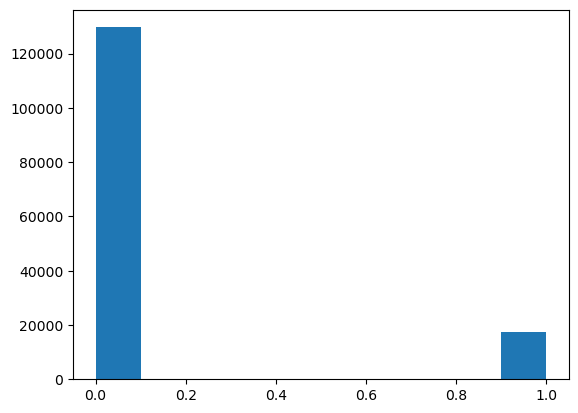

In [52]:
plt.hist(new_page_converted)

In [53]:
old_page_converted = np.random.choice([1 , 0] , size = len(df2_control) , p = [df2.converted.mean() , (1 - df2.converted.mean())] ) 

In [54]:
old_page_converted 

array([0, 0, 1, ..., 1, 0, 0])

(array([129350.,      0.,      0.,      0.,      0.,      0.,      0.,
             0.,      0.,  17852.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

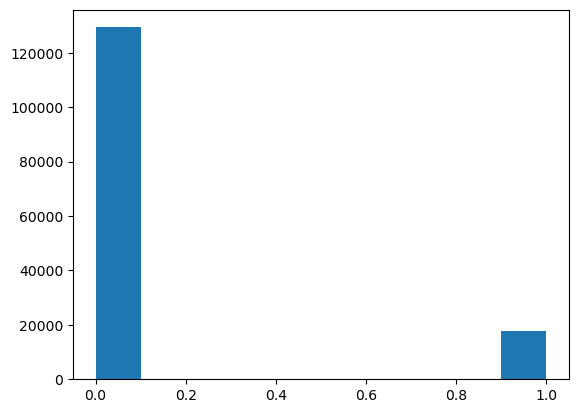

In [55]:
plt.hist(old_page_converted)

In [56]:
new_page_converted = np.random.binomial(len(df2_treatment), df2.converted.mean() , 10000) / len(df2_treatment)

In [57]:
old_page_converted = np.random.binomial(len(df2_control), df2.converted.mean() , 10000) / len(df2_control)

In [58]:
old_page_converted

array([0.11779052, 0.11939376, 0.11957039, ..., 0.12042635, 0.11911523,
       0.12053505])

In [59]:
p_diffs = new_page_converted - old_page_converted

In [60]:
p_diffs.mean()

-6.1045374811041805e-06

In [61]:
p_diffs

array([ 1.63830836e-03,  2.99878201e-04, -9.40289564e-05, ...,
       -2.49131936e-03,  9.38275571e-04, -2.76976285e-03])

In [62]:
ab_data_diff = df2_treatment['converted'].mean() - df2_control['converted'].mean()
ab_data_diff

-0.0014795997940775518

In [63]:
(p_diffs > ab_data_diff).mean() * 100

89.05

In [64]:
(p_diffs < ab_data_diff).mean() * 100

10.95

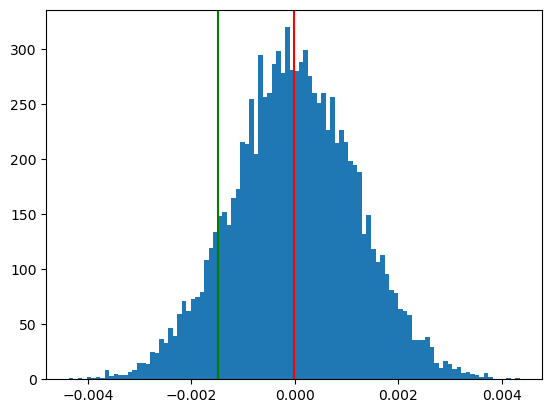

In [65]:
plt.hist(p_diffs, bins=100)
low = ab_data_diff
higth = p_diffs.mean()
plt.axvline(x=low, color='g')
plt.axvline(x=higth, color='r')

T_Test

In [66]:
import math
import pickle
import pandas as pd
import scipy.stats as stats

In [67]:
df = pd.read_csv('orange_trees.csv')
df.head()

,tree_number,oranges
0,1223,305.470796
1,1224,208.357224
2,1225,318.145987
3,1226,274.531146
4,1227,245.627474


<Axes: >

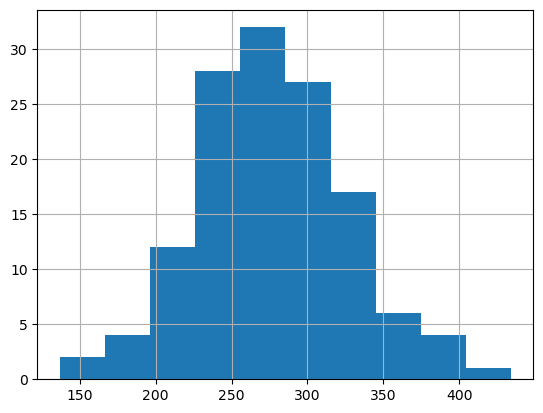

In [68]:
df['oranges'].hist()

In [69]:
df.describe()

,tree_number,oranges
count,133.00000,133.000000
mean,1289.00000,277.852803
std,38.53786,50.922243
min,1223.00000,137.023145
25%,1256.00000,237.696112
50%,1289.00000,279.470482
75%,1322.00000,312.079787
max,1355.00000,434.025714


In [70]:
population_mean = 271.93

In [71]:
stats.ttest_1samp(a = df['oranges'] , popmean = population_mean)

TtestResult(statistic=1.3413606837344207, pvalue=0.18210666026278088, df=132)

In [72]:
population_mean = 3.2
type(population_mean)

float

In [73]:
df_iets_98 = pd.read_csv('ielts_IR.csv')
df_iets_99 = pd.read_csv('ielts_IRQ.csv')

<Axes: >

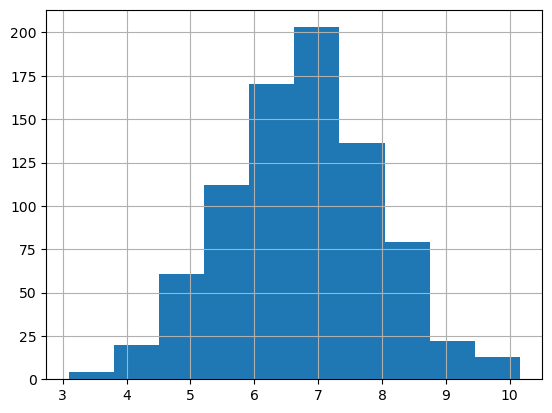

In [74]:
df_iets_98['ielts'].hist()

<Axes: >

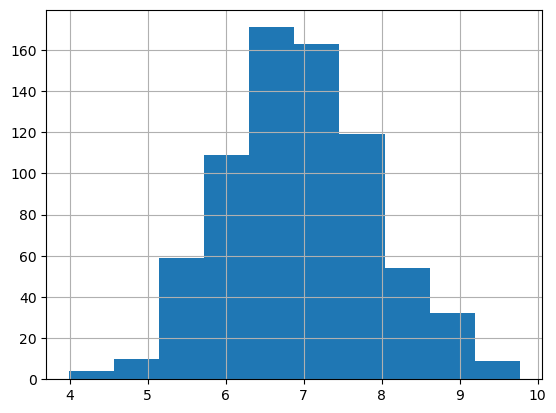

In [75]:
df_iets_99['ielts'].hist()

In [76]:
from scipy.stats import shapiro
shapiro(df_iets_99['ielts'])

ShapiroResult(statistic=0.9969674348831177, pvalue=0.1879747062921524)

In [77]:
df_iets_98.head()

,student_code,ielts
0,278917,6.330613
1,278918,7.275424
2,278919,7.012370
3,278920,5.564860
4,278921,5.607750


In [78]:
df_iets_99.head()

,student_code,ielts
0,3141112,8.725932
1,3141113,8.144126
2,3141114,6.419268
3,3141115,5.458811
4,3141116,9.303161


In [79]:
df_iets_98.describe()

,student_code,ielts
count,820.000000,820.000000
mean,279326.500000,6.754804
std,236.857904,1.178691
min,278917.000000,3.094945
25%,279121.750000,5.971638
50%,279326.500000,6.775687
75%,279531.250000,7.532372
max,279736.000000,10.159504


In [80]:
df_iets_99.describe()

,student_code,ielts
count,7.300000e+02,730.000000
mean,3.141476e+06,6.956215
std,2.108771e+02,0.964884
min,3.141112e+06,3.988457
25%,3.141294e+06,6.302632
50%,3.141476e+06,6.912297
75%,3.141659e+06,7.617062
max,3.141841e+06,9.772641


In [81]:
stats.ttest_ind( a = df_iets_98['ielts'] , b = df_iets_99['ielts'])

TtestResult(statistic=-3.6538217675570297, pvalue=0.00026698442613130104, df=1548.0)

In [82]:
df = pd.read_csv('weights_change.csv')
df.head()

,weight_before,weight_after
0,65.126024,69.579014
1,67.081931,70.142003
2,72.380314,67.482958
3,63.592077,64.890133
4,57.333414,70.430886


array([[<Axes: title={'center': 'weight_before'}>,
        <Axes: title={'center': 'weight_after'}>]], dtype=object)

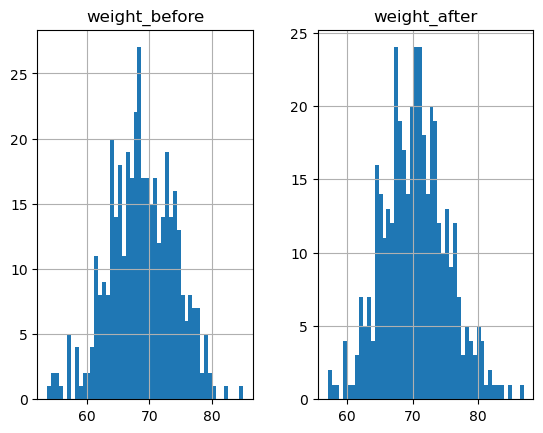

In [83]:
df.hist(bins = 50)

In [84]:
df.describe()

,weight_before,weight_after
count,410.000000,410.000000
mean,68.863354,70.425341
std,5.243526,4.975498
min,53.647173,56.991774
25%,65.136296,67.184292
50%,68.669384,70.455450
75%,72.729821,73.506856
max,85.056591,86.939716


In [85]:
stats.ttest_rel( a = df['weight_before'] , b = df['weight_after'])

TtestResult(statistic=-4.4624675042842386, pvalue=1.0488324309628723e-05, df=409)

ZTest

In [ ]:
from math import sqrt
import numpy as np


In [91]:
x_bar = 102
n = 100
sigma = 16
mu = 100

In [92]:
z = (x_bar - mu) / (sigma / sqrt(n))
print(z)

1.25


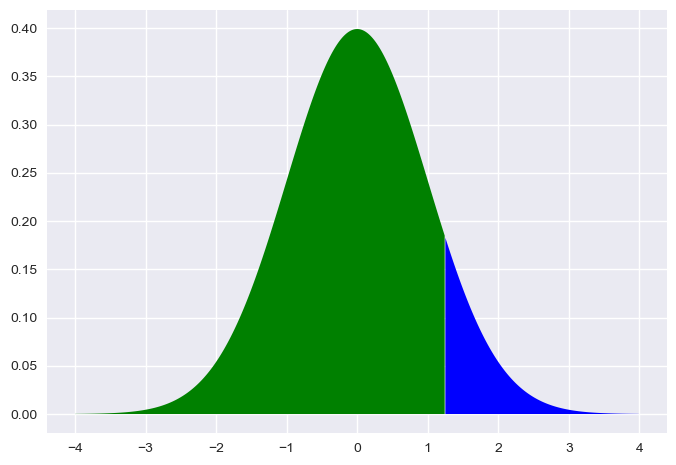

In [97]:
plt.style.use('seaborn-v0_8')

x_green = np.arange(-4, 1.25, 0.01)
plt.fill_between(x=x_green, y1=stats.norm.pdf(x_green), facecolor='green')

x_blue = np.arange(1.25, 4, 0.01)
plt.fill_between(x=x_blue, y1=stats.norm.pdf(x_blue), facecolor='blue')

In [98]:
stats.norm.cdf(z)

0.8943502263331446

In [99]:
p_value = 1 - stats.norm.cdf(z)

In [100]:
print(p_value)

0.10564977366685535


MannWithnyUTestsample

In [102]:
g1 = [20 , 23 , 21 , 25 , 18 , 17 , 18 , 24 , 20 , 24 , 23 , 19 ]
g2 = [24 , 25 , 21 , 22 , 23 , 18 , 17 , 28 , 24 , 27 , 21 , 23 ]

In [104]:
stats.mannwhitneyu(g1 , g2 , alternative = 'two-sided')

MannwhitneyuResult(statistic=50.0, pvalue=0.21138945901258455)

In [106]:
stats.mannwhitneyu(g1 , g2 , alternative = 'greater')

MannwhitneyuResult(statistic=50.0, pvalue=0.9045433311864579)

In [107]:
stats.mannwhitneyu(g1 , g2 , alternative = 'less')

MannwhitneyuResult(statistic=50.0, pvalue=0.10569472950629227)

Chi2

In [112]:
data = pd.read_csv('WA_Fn-UseC_-HR-Employee-Attrition.csv')
data.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [113]:
data.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [114]:
data.isnull().any()

Age                         False
Attrition                   False
BusinessTravel              False
DailyRate                   False
Department                  False
DistanceFromHome            False
Education                   False
EducationField              False
EmployeeCount               False
EmployeeNumber              False
EnvironmentSatisfaction     False
Gender                      False
HourlyRate                  False
JobInvolvement              False
JobLevel                    False
JobRole                     False
JobSatisfaction             False
MaritalStatus               False
MonthlyIncome               False
MonthlyRate                 False
NumCompaniesWorked          False
Over18                      False
OverTime                    False
PercentSalaryHike           False
PerformanceRating           False
RelationshipSatisfaction    False
StandardHours               False
StockOptionLevel            False
TotalWorkingYears           False
TrainingTimesL

In [115]:
data['JobSatisfaction'].value_counts()

JobSatisfaction
4    459
3    442
1    289
2    280
Name: count, dtype: int64

In [116]:
data['Attrition'].value_counts()

Attrition
No     1233
Yes     237
Name: count, dtype: int64

In [118]:
ct = pd.crosstab(data['Attrition'] , data['JobSatisfaction'] , margins = True)

In [119]:
ct

JobSatisfaction,1,2,3,4,All
Attrition,,,,,
No,223,234,369,407,1233
Yes,66,46,73,52,237
All,289,280,442,459,1470


In [120]:
ct.iloc[0] / 1233

JobSatisfaction
1      0.180860
2      0.189781
3      0.299270
4      0.330089
All    1.000000
Name: No, dtype: float64

In [121]:
ct.iloc[1] / 237

JobSatisfaction
1      0.278481
2      0.194093
3      0.308017
4      0.219409
All    1.000000
Name: Yes, dtype: float64

In [122]:
(ct.iloc[0] / 1233 ) - (ct.iloc[1] / 237)

JobSatisfaction
1     -0.097621
2     -0.004312
3     -0.008747
4      0.110680
All    0.000000
dtype: float64

In [123]:
obs = np.append(ct.iloc[0][ : -1].values , ct.iloc[1][ : -1].values)

In [124]:
obs

array([223, 234, 369, 407,  66,  46,  73,  52], dtype=int64)

In [130]:
row_sum = ct.iloc [ 0 : 2 , 4].values
row_sum

array([1233,  237], dtype=int64)

In [131]:
ct.loc['All' , 'All']

1470

In [132]:
exp = []
for j in range(2):
    for val in ct.iloc[2, : -1].values:
        print(val, ' * ', row_sum[j], ' / ', ct.loc['All', 'All'], ' = ', val * row_sum[j] / ct.loc['All', 'All'])
        exp.append(val * row_sum[j] / ct.loc['All', 'All'])

289  *  1233  /  1470  =  242.4061224489796
280  *  1233  /  1470  =  234.85714285714286
442  *  1233  /  1470  =  370.7387755102041
459  *  1233  /  1470  =  384.99795918367346
289  *  237  /  1470  =  46.593877551020405
280  *  237  /  1470  =  45.142857142857146
442  *  237  /  1470  =  71.26122448979592
459  *  237  /  1470  =  74.00204081632653


In [133]:
exp

[242.4061224489796,
 234.85714285714286,
 370.7387755102041,
 384.99795918367346,
 46.593877551020405,
 45.142857142857146,
 71.26122448979592,
 74.00204081632653]

In [134]:
ct.iloc[ 2 , : -1].values

array([289, 280, 442, 459], dtype=int64)

In [135]:
obs

array([223, 234, 369, 407,  66,  46,  73,  52], dtype=int64)

In [137]:
exp

[242.4061224489796,
 234.85714285714286,
 370.7387755102041,
 384.99795918367346,
 46.593877551020405,
 45.142857142857146,
 71.26122448979592,
 74.00204081632653]

In [138]:
((obs - exp ) ** 2 / exp ).sum()

17.505077010348

In [141]:
dof = (len(row_sum) - 1) * (len(ct.iloc[ 2 , : -1].values) - 1)

In [142]:
dof

3

In [143]:
1 - stats.chi2.cdf(((obs - exp) ** 2/ exp).sum() , dof)

0.000556300451038716

In [145]:
#p_value = 0.000556300451038716


In [146]:
ct

JobSatisfaction,1,2,3,4,All
Attrition,,,,,
No,223,234,369,407,1233
Yes,66,46,73,52,237
All,289,280,442,459,1470


In [147]:
d = np.array([ct.iloc[0][ : -1].values , ct.iloc[1][ : -1].values])
d

array([[223, 234, 369, 407],
       [ 66,  46,  73,  52]], dtype=int64)

In [149]:
stats.chi2_contingency(d)

Chi2ContingencyResult(statistic=17.505077010348, pvalue=0.0005563004510387556, dof=3, expected_freq=array([[242.40612245, 234.85714286, 370.73877551, 384.99795918],
       [ 46.59387755,  45.14285714,  71.26122449,  74.00204082]]))

In [150]:
from scipy.stats import chisquare

In [151]:
chisquare(d)

Power_divergenceResult(statistic=array([ 85.29065744, 126.22857143, 198.22624434, 274.56427015]), pvalue=array([2.57577384e-20, 2.74031376e-29, 5.09229443e-45, 1.14862090e-61]))

In [152]:
ct = pd.crosstab(data['Attrition'] , data['Education'] , margins = True)

In [153]:
ct

Education,1,2,3,4,5,All
Attrition,,,,,,
No,139,238,473,340,43,1233
Yes,31,44,99,58,5,237
All,170,282,572,398,48,1470


In [154]:
d = np.array([ct.iloc[0][ : -1].values , ct.iloc[1][ : -1].values])
d

array([[139, 238, 473, 340,  43],
       [ 31,  44,  99,  58,   5]], dtype=int64)

In [156]:
stats.chi2_contingency(d)

Chi2ContingencyResult(statistic=3.0739613982367193, pvalue=0.5455253376565949, dof=4, expected_freq=array([[142.59183673, 236.53469388, 479.77959184, 333.83265306,
         40.26122449],
       [ 27.40816327,  45.46530612,  92.22040816,  64.16734694,
          7.73877551]]))

Normality Test

In [157]:
from scipy.stats import shapiro

In [158]:
data = np.random.normal( loc = 20 , scale = 5 , size = 1000)
data

array([27.10347314, 23.4964484 , 13.60774486, 18.17716627, 17.07350988,
        8.8543312 , 21.9758186 , 17.28131486, 21.29608911, 23.20856538,
       22.64275425, 13.19023018, 22.77762302, 20.99997208, 18.04103477,
       16.58984268, 20.59068576, 23.26555268, 22.11178444, 14.49928533,
       19.91070921, 15.71675173, 11.11774516, 26.91690811, 21.13933065,
       22.06405781, 26.02676424, 24.73118509, 19.30119012, 18.13760083,
       27.16631604, 20.70804145, 19.71429969, 18.56120599, 12.77453083,
       12.79526146, 15.91113899, 13.91480903, 21.54437154, 20.79282528,
       19.76121052, 15.95193705, 20.70450007, 15.69646255, 32.26785218,
       17.37787116, 16.38114119, 21.67490162, 17.13203737, 27.38254789,
       12.56753016, 20.26573555, 28.60955723, 17.253484  , 23.04970183,
       22.24737281, 20.54747187, 14.30036006, 22.50526803, 21.33634193,
       13.3619828 ,  7.81779323, 19.83200447,  6.89295651,  5.64824498,
       20.90187572, 29.73241687, 11.45716746, 19.25953556, 22.14

In [159]:
shapiro(data)

ShapiroResult(statistic=0.9984179139137268, pvalue=0.5021660327911377)

In [160]:
import pylab

((array([-3.19758950e+00, -2.93237785e+00, -2.78437841e+00, -2.67999560e+00,
         -2.59855946e+00, -2.53139899e+00, -2.47402263e+00, -2.42379214e+00,
         -2.37902149e+00, -2.33856546e+00, -2.30160949e+00, -2.26755284e+00,
         -2.23593934e+00, -2.20641415e+00, -2.17869564e+00, -2.15255643e+00,
         -2.12781017e+00, -2.10430217e+00, -2.08190261e+00, -2.06050135e+00,
         -2.04000420e+00, -2.02032992e+00, -2.00140792e+00, -1.98317650e+00,
         -1.96558137e+00, -1.94857451e+00, -1.93211325e+00, -1.91615948e+00,
         -1.90067901e+00, -1.88564107e+00, -1.87101783e+00, -1.85678408e+00,
         -1.84291686e+00, -1.82939524e+00, -1.81620005e+00, -1.80331371e+00,
         -1.79072004e+00, -1.77840415e+00, -1.76635224e+00, -1.75455157e+00,
         -1.74299028e+00, -1.73165738e+00, -1.72054262e+00, -1.70963644e+00,
         -1.69892989e+00, -1.68841463e+00, -1.67808281e+00, -1.66792707e+00,
         -1.65794051e+00, -1.64811661e+00, -1.63844924e+00, -1.62893261e+00,

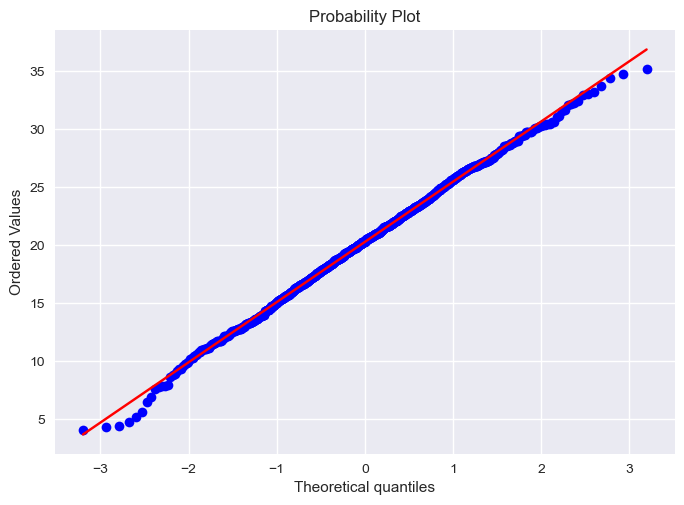

In [161]:
stats.probplot(data , dist = 'norm', plot = pylab )